In [4]:
import os, sys
cur_directory = os.getcwd()
project_folder = os.path.abspath(os.path.join(cur_directory, os.pardir, os.pardir))
save_directory = os.path.join(cur_directory, 'saved')
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [5]:
import numpy as np
from numpy import linalg as la
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

# Sweep over stimuli

In [3]:
V_width = 1
V_E_buffer = 0
E_width = 1
stim_array = np.array(range(5))
N_training_repeats = 5
cg_params = {
    "order": 1,
    "output_dim": 20
}

critic_params = {
    "hidden_dim": 32,
    "embed_dim": 93,
    "layers": 0,
    "activation": None,
}

opt_params = {"track_quantities": False, "quiet": True, "iterations": 5}
mi_measurement_params = {'quiet':True, 'batch_size':500, 'N_batches':500}

train_fraction = 0.5
samp_keep = 1


## Prepare data

## Run analysis

In [10]:
experiment_dims = (len(stim_array), N_training_repeats,)
mi_averages_test = np.zeros(experiment_dims)
mi_averages_train = np.zeros(experiment_dims)
mi_stdevs_train = np.zeros(experiment_dims)
mi_stdevs_test = np.zeros(experiment_dims)

coarse_grainer_array = np.zeros(experiment_dims, dtype=object)
critic_function_array = np.zeros(experiment_dims, dtype=object)
train_points = np.zeros(experiment_dims, dtype=object)
test_points = np.zeros(experiment_dims, dtype=object)

for n in tqdm(stim_array):

    data_path = os.path.join(project_folder, 'data', 'nat_scenes_data')
    D = ds.DataNatScenes(data_path, mov_ind=n)
    print(f'current stimulus is {D.movname}')
    D.trim(20)
    V, E = D.create_V_and_E_datasets(V_width, V_E_buffer, E_width, samp_keep=samp_keep)
    
    for training_repeat in range(N_training_repeats):
        cur_inds = (n, training_repeat)
        coarse_grainer = mds.PolynomialLayer(**cg_params)
        critic_function = mds.SeparableCritic(**critic_params)

        # make training and test subsets
        V.reset()
        E.reset()
        current_train_points, current_test_points = tools.generate_train_test_indices(
            V.P, train_fraction
        )
        V.subset_points(current_train_points)
        E.subset_points(current_train_points)
        train_points[cur_inds] = current_train_points
        test_points[cur_inds] = current_test_points

        # Train current
        als.IB(
            X=V.X,
            Y=E.X,
            coarse_grainer=coarse_grainer,
            critic_function=critic_function,
            **opt_params
        )

        # Measure InfoNCE for train
        T_train = coarse_grainer(V.X.T).numpy().T
        mi_train = als.MI_NCE(
            X=T_train, Y=E.X, critic_function=critic_function, **mi_measurement_params
        )
        mi_averages_train[cur_inds] = mi_train["mi"]
        mi_stdevs_train[cur_inds] = mi_train["mi_stdev"]

        # Measure InfoNCE for test
        V.reset()
        E.reset()
        V.subset_points(current_test_points)
        E.subset_points(current_test_points)
        T_test = coarse_grainer(V.X.T).numpy().T
        mi_test = als.MI_NCE(
            X=T_test, Y=E.X, critic_function=critic_function, **mi_measurement_params
        )
        mi_averages_test[cur_inds] = mi_test["mi"]
        mi_stdevs_test[cur_inds] = mi_test["mi_stdev"]

        coarse_grainer_array[cur_inds] = coarse_grainer
        critic_function_array[cur_inds] = critic_function

  0%|          | 0/5 [00:00<?, ?it/s]

current stimulus is bushes


 20%|██        | 1/5 [00:18<01:14, 18.54s/it]

current stimulus is water


 40%|████      | 2/5 [00:35<00:51, 17.32s/it]

current stimulus is leaves


 60%|██████    | 3/5 [00:52<00:34, 17.38s/it]

current stimulus is fish


 80%|████████  | 4/5 [01:09<00:17, 17.32s/it]

current stimulus is opticflow


100%|██████████| 5/5 [01:24<00:00, 16.90s/it]


In [17]:
coarse_grainer_type = type(coarse_grainer)
critic_type = type(critic_function)
save_vars = {
    "mi_measurement_params",
    "opt_params",
    "cg_params",
    "N_training_repeats",
    "critic_params",
    "V_width",
    "V_E_buffer",
    "E_width",
    "train_fraction",
    "samp_keep",
    "mi_averages_train",
    "mi_averages_test",
    "mi_stdevs_train",
    "mi_stdevs_test",
    "train_points",
    "test_points",
    "critic_type",
    "coarse_grainer_type"
}
local_dict = locals()
output_data = {k: local_dict[k] for k in save_vars}

In [18]:
save_directory

'/Users/adamkline/Projects/archive/metaneurons/analyses/architecture tests/saved'

In [23]:
# save things
timestamp = strftime("%Y.%m.%d %Hh %Mm %Ss.dat",gmtime())
# full_file_path = os.path.join(save_directory, strftime("%Y.%m.%d %Hh %Mm %Ss",gmtime())+'.dat')

full_file_path = os.path.join(save_directory, f'linear critic {V_width, V_E_buffer, E_width}.dat')
# full_file_path = os.path.join(save_directory, stim, prepend + 'all neurons, trim 60.dat')
print(f"data will be saved to:\n{full_file_path}")

data will be saved to:
/Users/adamkline/Projects/archive/metaneurons/analyses/architecture tests/saved/linear critic (1, 0, 1).dat


In [24]:
os.makedirs(os.path.dirname(full_file_path), exist_ok=True)
with open(full_file_path, 'wb+') as f:
            pickle.dump(output_data, f)
tools.record_parameters(full_file_path, output_data)

### Reload and plot

In [6]:
# load_path = 'analyses/architecture tests/saved/linear critic (1, 0, 1).dat'
# load_path = project_folder + f'analyses/architecture tests/saved/linear critic (1, 0, 1).dat'
load_path = project_folder + '/analyses/architecture tests/saved/linear critic (1, 0, 1).dat'
with open(load_path, 'rb') as f:
    data_dict = pickle.load(f)
data = Namespace(**data_dict)

In [7]:
x = np.arange(5)
y = np.mean(data.mi_averages_test, axis=-1) / np.log(2)
yerr = np.sqrt(np.var(data.mi_averages_test, axis=-1) + np.sqrt(np.mean(data.mi_stdevs_test**2, 1))) / np.log(2)

<ErrorbarContainer object of 3 artists>

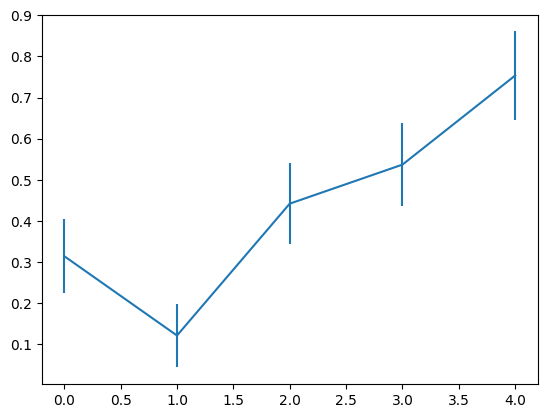

In [8]:
plt.errorbar(x, y, yerr)

In [9]:
y

array([0.31435488, 0.1215221 , 0.44200636, 0.53688754, 0.75338672])

In [10]:
yerr

array([0.09058613, 0.07767019, 0.09810652, 0.10006613, 0.10708316])

# Train/test validation - epochs

In [29]:
mov_ind = 4

In [30]:
data_path = os.path.join(project_folder, 'data', 'nat_scenes_data')
D = ds.DataNatScenes(data_path, mov_ind=mov_ind)
print(f'current stimulus is {D.movname}')
mov_ind = D.mov_ind

current stimulus is opticflow


In [ ]:
V_width = 5
V_E_buffer = 0
E_width = 1

N_training_repeats = 1
iterations_array = np.array([1, 5, 10,])
cg_params = {
    "order": 1,
    "output_dim": 20
}

critic_params = {
    "hidden_dim": 32,
    "embed_dim": 93,
    "layers": 0,
    "activation": None,
}

# opt_params = {"track_quantities": False, "quiet": True, "iterations": 5}
opt_params = {"track_quantities": False, "quiet": True}
mi_measurement_params = {'quiet':True, 'batch_size':500, 'N_batches':500}


train_fraction = 0.5
samp_keep = 1

## Prepare data

In [38]:
D.reset()
D.trim(20)
V, E = D.create_V_and_E_datasets(V_width, V_E_buffer, E_width, samp_keep=samp_keep)

## Run analysis

In [39]:
experiment_dims = (len(iterations_array), N_training_repeats,)
mi_averages_test = np.zeros(experiment_dims)
mi_averages_train = np.zeros(experiment_dims)
mi_stdevs_train = np.zeros(experiment_dims)
mi_stdevs_test = np.zeros(experiment_dims)

coarse_grainer_array = np.zeros(experiment_dims, dtype=object)
critic_function_array = np.zeros(experiment_dims, dtype=object)
train_points = np.zeros(experiment_dims, dtype=object)
test_points = np.zeros(experiment_dims, dtype=object)

for n, iterations in tqdm(enumerate(iterations_array)):
    for training_repeat in range(N_training_repeats):
        cur_inds = (n, training_repeat)
        coarse_grainer = mds.PolynomialLayer(**cg_params)
        critic_function = mds.SeparableCritic(**critic_params)

        # make training and test subsets
        V.reset()
        E.reset()
        current_train_points, current_test_points = tools.generate_train_test_indices(
            V.P, train_fraction
        )
        V.subset_points(current_train_points)
        E.subset_points(current_train_points)
        train_points[cur_inds] = current_train_points
        test_points[cur_inds] = current_test_points

        # Train current
        opt_params["iterations"] = iterations
        als.IB(
            X=V.X,
            Y=E.X,
            coarse_grainer=coarse_grainer,
            critic_function=critic_function,
            **opt_params
        )

        # Measure InfoNCE for train
        T_train = coarse_grainer(V.X.T).numpy().T
        mi_train = als.MI_NCE(
            X=T_train, Y=E.X, critic_function=critic_function, **mi_measurement_params
        )
        mi_averages_train[cur_inds] = mi_train["mi"]
        mi_stdevs_train[cur_inds] = mi_train["mi_stdev"]

        # Measure InfoNCE for test
        V.reset()
        E.reset()
        V.subset_points(current_test_points)
        E.subset_points(current_test_points)
        T_test = coarse_grainer(V.X.T).numpy().T
        mi_test = als.MI_NCE(
            X=T_test, Y=E.X, critic_function=critic_function, **mi_measurement_params
        )
        mi_averages_test[cur_inds] = mi_test["mi"]
        mi_stdevs_test[cur_inds] = mi_test["mi_stdev"]

        coarse_grainer_array[cur_inds] = coarse_grainer
        critic_function_array[cur_inds] = critic_function

3it [00:12,  4.01s/it]


In [43]:
mi_averages_test / np.log(2), mi_stdevs_test / np.log(2)

(array([[0.93032884],
        [1.05112232],
        [1.013277  ]]),
 array([[0.00788288],
        [0.00994004],
        [0.0115772 ]]))

In [44]:
mi_averages_train / np.log(2), mi_stdevs_train / np.log(2)

(array([[1.0600766 ],
        [1.44152644],
        [1.52937272]]),
 array([[0.00769767],
        [0.01085763],
        [0.01101137]]))

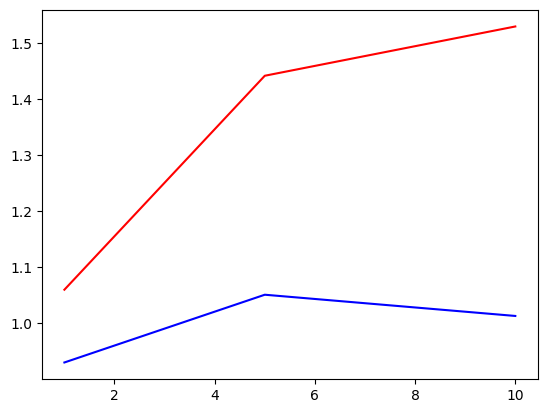

In [45]:
plt.plot(iterations_array, mi_averages_test/np.log(2), color='blue')
plt.plot(iterations_array, mi_averages_train/np.log(2), color='red')

In [15]:
u = critic_function._h
Wu = u.weights[0].numpy()
bu = u.weights[0].numpy()

v = critic_function._g
Wv = v.weights[0].numpy()
bv = v.weights[0].numpy()

# W = critic_function._h.layers[0].weights[0]
# b = critic_function._h.layers[0].weights[0]

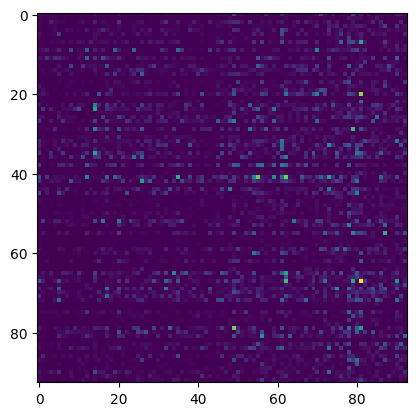

In [16]:
plt.imshow(Wu.T**2)

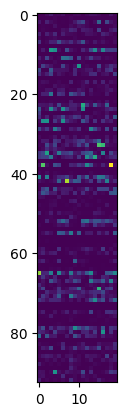

In [17]:
plt.imshow(Wv.T**2)

In [24]:
A = Wv @ Wu.T

In [25]:
A.shape

(93, 20)